In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

from scipy.stats import norm

In [2]:
df = pd.read_csv('data89.csv')
x = df[['x']].to_numpy()
y = df['y'].to_numpy()

ks = np.arange(1, 21)
part_counts = [5, 10, 20]

errors_pr = [[0 for k in ks] for _ in part_counts]
errors_knn = [[0 for k in ks] for _ in part_counts]
losses_pr = [[0 for k in ks] for _ in part_counts]
losses_knn = [[0 for k in ks] for _ in part_counts]

rows = []
p_vals = []

for i, pc in enumerate(part_counts):
    kf = KFold(n_splits=pc, shuffle=True, random_state=1)

    for k in ks:
        loss_p, loss_k = [], []

        for train_ids, test_ids in kf.split(x):
            x_train, x_test = x[train_ids], x[test_ids]
            y_train, y_test = y[train_ids], y[test_ids]

            pr = make_pipeline(
                StandardScaler(),
                PolynomialFeatures(degree=int(k)),
                LinearRegression()
            )
            knn = KNeighborsRegressor(n_neighbors=int(k))

            pr.fit(x_train, y_train)
            knn.fit(x_train, y_train)

            loss_p.append((y_test - pr.predict(x_test)) ** 2)
            loss_k.append((y_test - knn.predict(x_test)) ** 2)

        errors_pr[i][k-1] = np.mean([v.mean() for v in loss_p])
        errors_knn[i][k-1] = np.mean([v.mean() for v in loss_k])
        losses_pr[i][k-1] = loss_p
        losses_knn[i][k-1] = loss_k

    kp = np.argmin(errors_pr[i])
    kk = np.argmin(errors_knn[i])

    for name, errors, losses, best in [
        ('Полин. регр.', errors_pr, losses_pr, kp),
        ('KNN', errors_knn, losses_knn, kk)
    ]:
        error = errors[i][best]
        variance = np.mean([
            np.var(v, ddof=1) for v in losses[i][best]
        ])
        margin = norm.ppf(0.975) * np.sqrt(variance / len(y))
        rows.append([
            name, pc, best + 1, error,
            f'[{error - margin:.3f}; {error + margin:.3f}]'
        ])

    diff = [
        p - k for p, k in zip(losses_pr[i][kp], losses_knn[i][kk])
    ]
    sigma_squared = np.mean([np.var(v, ddof=1) for v in diff])
    z = (
        np.sqrt(len(y))
        * (errors_pr[i][kp] - errors_knn[i][kk])
        / np.sqrt(sigma_squared)
    )
    p_vals.append(norm.cdf(z))

table = pd.DataFrame(rows, columns=[
    'Модель', 'Число частей', 'Лучший k', 'Ошибка', '95% ДИ'
]).iloc[[0, 2, 4, 1, 3, 5]]

display(table.style.format({'Ошибка': '{:.3f}'}).hide(axis='index'))
display(pd.DataFrame({'Число частей': part_counts, 'p-value': p_vals}))




        




Модель,Число частей,Лучший k,Ошибка,95% ДИ
Полин. регр.,5,10,1.182,[0.846; 1.518]
Полин. регр.,10,10,1.182,[0.854; 1.510]
Полин. регр.,20,14,1.174,[0.838; 1.509]
KNN,5,8,1.233,[0.884; 1.582]
KNN,10,13,1.238,[0.891; 1.585]
KNN,20,13,1.236,[0.898; 1.574]


,Число частей,p-value
0,5,0.246871
1,10,0.252770
2,20,0.205413


9


In [3]:


part_counts = [5, 10]
names = ['Полин. регр.', 'KNN']

# [модель][вариант CV][эксперимент]
best_ks = np.zeros((2, 2, 100), dtype=int)
best_errors = np.zeros((2, 2, 100))

for exp in range(100):
    for i, pc in enumerate(part_counts):
        splits = list(
            KFold(n_splits=pc, shuffle=True, random_state=exp).split(x)
        )
        errors = [[], []]

        for k in ks:
            models = [
                make_pipeline(
                    StandardScaler(),
                    PolynomialFeatures(degree=int(k)),
                    LinearRegression()
                ),
                KNeighborsRegressor(n_neighbors=int(k))
            ]

            for m, model in enumerate(models):
                error = -cross_val_score(
                    model, x, y, cv=splits,
                    scoring='neg_mean_squared_error'
                ).mean()
                errors[m].append(error)

        for m in range(2):
            best = np.argmin(errors[m])
            best_ks[m, i, exp] = ks[best]
            best_errors[m, i, exp] = errors[m][best]

    if (exp + 1) % 10 == 0:
        print(f'{exp + 1}/100')

10/100
20/100
30/100
40/100
50/100
60/100
70/100
80/100
90/100
100/100


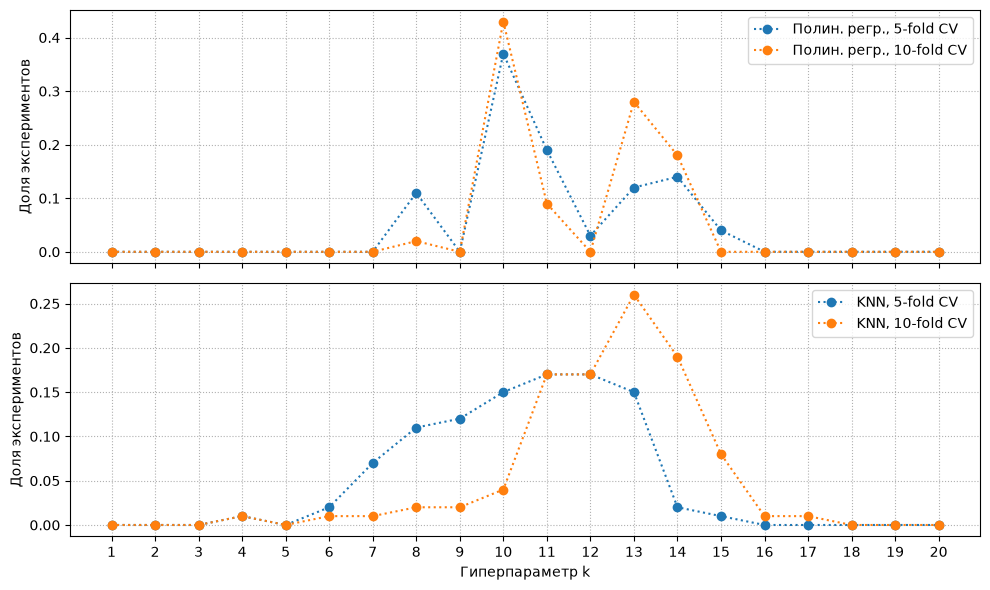

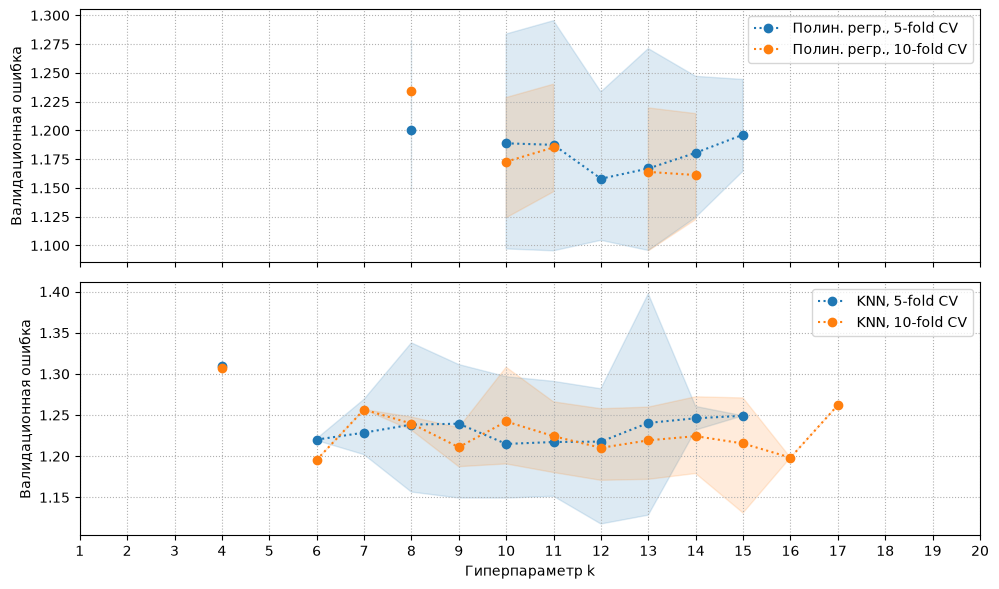

In [4]:
for plot_type in ['Доля экспериментов', 'Валидационная ошибка']:
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    for m, ax in enumerate(axes):
        for i, pc in enumerate(part_counts):
            values = np.full(len(ks), np.nan)
            lower = values.copy()
            upper = values.copy()

            for j, k in enumerate(ks):
                mask = best_ks[m, i] == k

                if plot_type == 'Доля экспериментов':
                    values[j] = mask.mean()
                elif mask.any():
                    errors = best_errors[m, i][mask]
                    values[j] = errors.mean()
                    lower[j], upper[j] = np.quantile(errors, [0.05, 0.95])

            line, = ax.plot(
                ks, values, 'o:', label=f'{names[m]}, {pc}-fold CV'
            )

            if plot_type == 'Валидационная ошибка':
                ax.fill_between(
                    ks, lower, upper,
                    color=line.get_color(), alpha=0.15
                )

        ax.set_ylabel(plot_type)
        ax.grid(True, linestyle=':')
        ax.legend()

    axes[-1].set_xticks(ks)
    axes[-1].set_xlabel('Гиперпараметр k')
    plt.tight_layout()
    plt.show()